# Pantree: what the data says

This notebook explores the generated Pantree warehouse: sales over time, the February 2025 price change,
the shopping funnel, payments, returns, marketing channels and repeat customers. It ends with the
recommendation evaluation results.

Every number below is computed from the data when the notebook runs. The data is simulated (see the README),
so the findings describe how this shop behaves, not a real business.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
DATA = ROOT / "data"
read = lambda name: pd.read_parquet(DATA / f"{name}.parquet")

# Chart style: one categorical palette in fixed order, thin marks, recessive grid.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.figsize": (9, 3.6), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "lines.linewidth": 2, "font.size": 9,
})

from matplotlib.ticker import PercentFormatter

def hbar(series, title, fmt="{:.1%}", color=SERIES[0], sort=True):
    s = series.sort_values() if sort else series
    fig, ax = plt.subplots(figsize=(9, 0.38 * len(s) + 0.9))
    ax.barh(s.index.astype(str), s.values, color=color, height=0.62)
    for y, v in enumerate(s.values):
        ax.text(v, y, "  " + fmt.format(v), va="center", color=INK, fontsize=8.5)
    ax.set_title(title); ax.grid(axis="y", visible=False); ax.margins(x=0.12)
    if "%" in fmt:
        ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    plt.tight_layout(); plt.show()

tx = read("transactions"); tx["order_timestamp"] = pd.to_datetime(tx["order_timestamp"])
orders = read("orders"); orders["order_timestamp"] = pd.to_datetime(orders["order_timestamp"])
customers = read("customer_master"); products = read("product_master")
realized = orders[orders["is_realized"]]

## 1. The dataset at a glance

In [2]:
sizes = {name: len(read(name)) for name in [
    "customer_master", "product_master", "orders", "transactions", "clickstream",
    "inventory", "returns", "product_reviews", "support_contacts"]}
print(pd.Series(sizes, name="rows").map("{:,}".format).to_string())
buyers = realized["customer_id"].nunique()
print(f"\nCustomers who bought at least once: {buyers:,} of {len(customers):,} ({buyers/len(customers):.1%})")
print(f"Realized revenue: ₹{realized['realized_revenue'].sum():,.0f} from {len(realized):,} paid orders")
print(f"Average order value: ₹{realized['realized_revenue'].mean():,.0f}")

customer_master        33,060
product_master         10,000
orders                 26,641
transactions           42,215
clickstream         5,452,199
inventory           5,460,000
returns                 6,517
product_reviews        16,163
support_contacts        1,743

Customers who bought at least once: 10,615 of 33,060 (32.1%)
Realized revenue: ₹81,032,112 from 24,721 paid orders
Average order value: ₹3,278


## 2. Sales over time
Monthly realized revenue. Shaded months are festival and sale periods configured in the simulator.
Note the steady growth: new customers join every month, so later months are naturally larger.

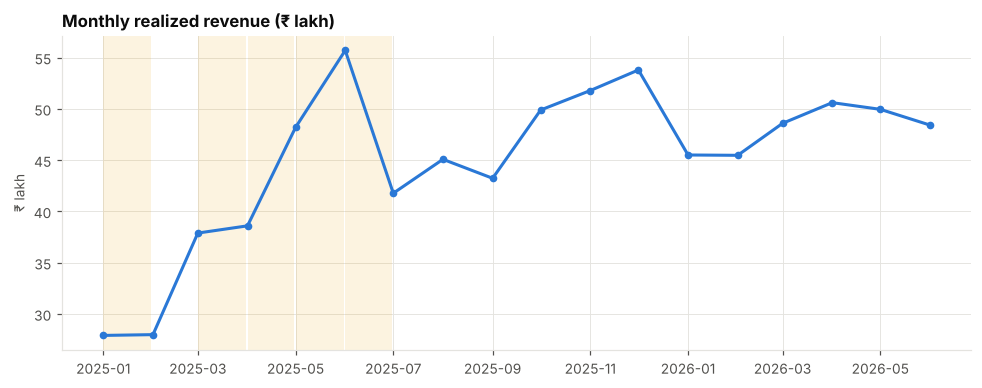

Best month: Jun 2025 (₹55.7 lakh); weakest: Jan 2025 (₹27.9 lakh)
Festival calendar in generators/config.py covers: 2025-01, 2025-03, 2025-04, 2025-05, 2025-06; last configured month 2025-06
12 months after 2025-06 (including Oct-Nov 2025 Diwali) have no festival boost configured.
A raw festival vs non-festival comparison is therefore misleading: the shop also grows over time,
so early (festival-flagged) months look weaker. Extending the calendar is listed as a next step.


In [3]:
monthly = realized.set_index("order_timestamp")["realized_revenue"].resample("MS").sum()
monthly = monthly.iloc[:-1] if monthly.index[-1].month == realized["order_timestamp"].max().month and realized["order_timestamp"].max().day < 25 else monthly
import sys; sys.path.insert(0, str(ROOT / "generators")); import config as C
fig, ax = plt.subplots()
for month in monthly.index:
    if month.strftime("%Y-%m") in C.FESTIVALS:
        ax.axvspan(month, month + pd.offsets.MonthEnd(0), color="#eda100", alpha=0.12, lw=0)
ax.plot(monthly.index, monthly.values / 1e5, color=SERIES[0], marker="o", markersize=4)
ax.set_title("Monthly realized revenue (₹ lakh)"); ax.set_ylabel("₹ lakh")
plt.tight_layout(); plt.show()
best = monthly.idxmax()
print(f"Best month: {best:%b %Y} (₹{monthly.max()/1e5:.1f} lakh); weakest: {monthly.idxmin():%b %Y} (₹{monthly.min()/1e5:.1f} lakh)")
covered = sorted(m for m in C.FESTIVALS if m >= monthly.index.min().strftime("%Y-%m"))
print(f"Festival calendar in generators/config.py covers: {', '.join(covered)}; last configured month {max(C.FESTIVALS)}")
late = [m for m in monthly.index if m.strftime("%Y-%m") > max(C.FESTIVALS)]
print(f"{len(late)} months after {max(C.FESTIVALS)} (including Oct-Nov 2025 Diwali) have no festival boost configured.")
print("A raw festival vs non-festival comparison is therefore misleading: the shop also grows over time,")
print("so early (festival-flagged) months look weaker. Extending the calendar is listed as a next step.")

## 3. The February 2025 price change
On 1 Feb 2025 prices rose 6–11%. Below: what shoppers paid relative to the listed price, and how many
orders each active customer placed per month.

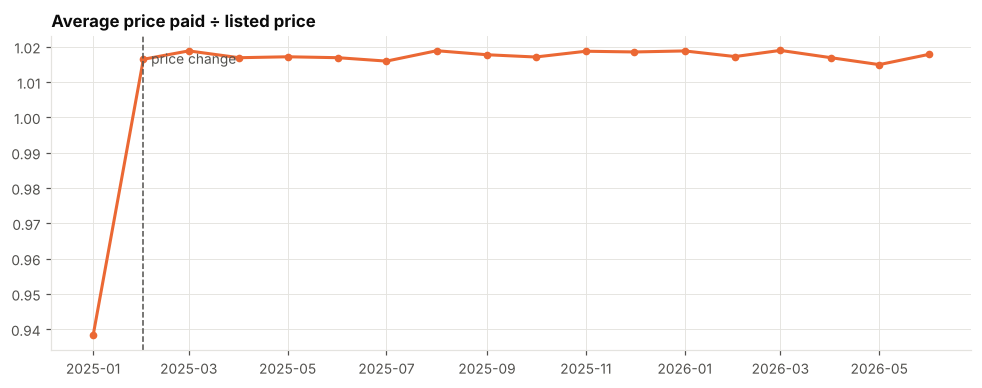

Paid/listed price: 0.938 before vs 1.018 after (+8.5%)


In [4]:
tx["paid_vs_list"] = tx["unit_selling_price"] / tx["listed_price"]
paid = tx[tx["net_item_value"] > 0].set_index("order_timestamp")["paid_vs_list"].resample("MS").mean()
fig, ax = plt.subplots()
ax.plot(paid.index, paid.values, color=SERIES[1], marker="o", markersize=4)
ax.axvline(pd.Timestamp(C.SHOCK_DATE), color=MUTED, lw=1, ls="--"); ax.text(pd.Timestamp(C.SHOCK_DATE), paid.max(), "  price change", color=MUTED, va="top")
ax.set_title("Average price paid ÷ listed price"); plt.tight_layout(); plt.show()
before = tx[(tx.order_timestamp < C.SHOCK_DATE) & (tx.net_item_value > 0)]["paid_vs_list"].mean()
after = tx[(tx.order_timestamp >= C.SHOCK_DATE) & (tx.net_item_value > 0)]["paid_vs_list"].mean()
print(f"Paid/listed price: {before:.3f} before vs {after:.3f} after ({after/before - 1:+.1%})")

## 4. The shopping funnel

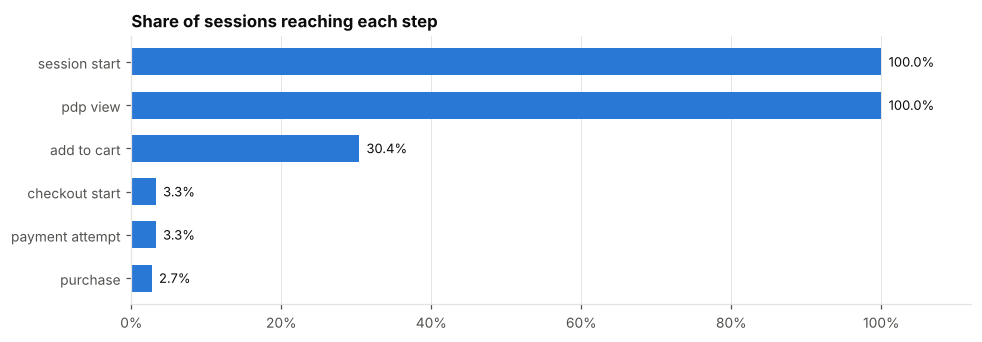

Sessions: 815,666; conversion to purchase: 2.72%
Cart → purchase: 9.0%


In [5]:
cs = read("clickstream")[["session_id", "event_type"]]
steps = ["session_start", "pdp_view", "add_to_cart", "checkout_start", "payment_attempt", "purchase"]
reached = {s: cs.loc[cs.event_type.eq(s), "session_id"].nunique() for s in steps}
total = reached["session_start"]
funnel = pd.Series({s.replace("_", " "): reached[s] / total for s in steps})
hbar(funnel.iloc[::-1], "Share of sessions reaching each step", sort=False)
print(f"Sessions: {total:,}; conversion to purchase: {reached['purchase']/total:.2%}")
print(f"Cart → purchase: {reached['purchase']/reached['add_to_cart']:.1%}")

## 5. Payments and delivery problems

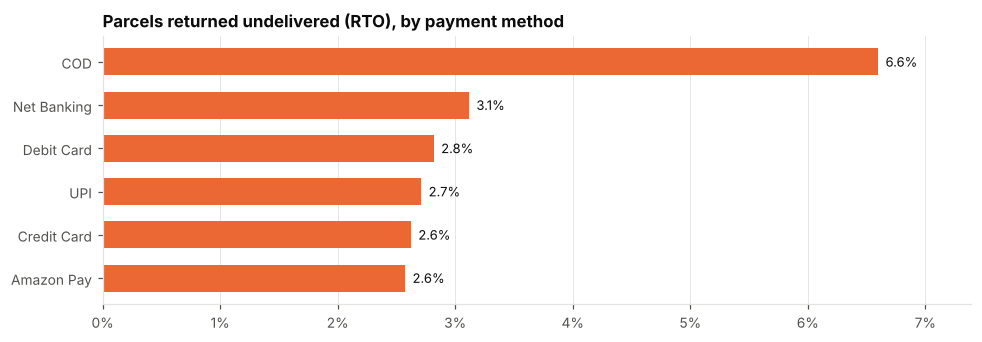

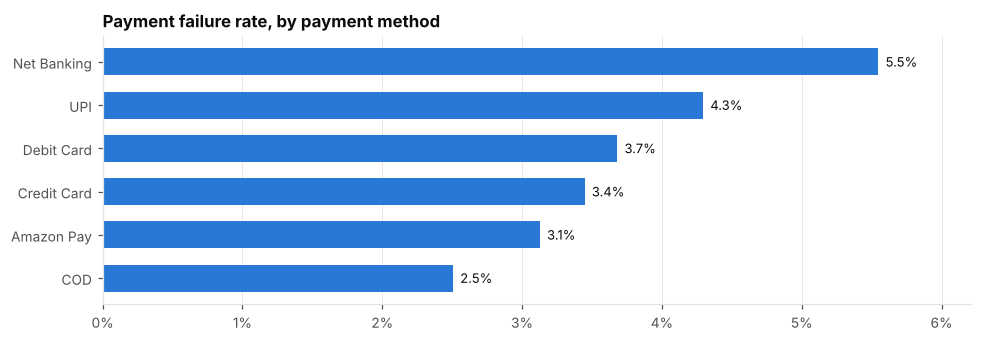

Cash on delivery RTO rate 6.6% vs 2.7% for prepaid (2.4×)


In [6]:
by_method = tx.groupby("payment_method").agg(
    failed=("payment_status", lambda s: s.eq("Failed").mean()),
    returned_to_origin=("order_status", lambda s: s.eq("RTO").mean()))
hbar(by_method["returned_to_origin"], "Parcels returned undelivered (RTO), by payment method", color=SERIES[1])
hbar(by_method["failed"], "Payment failure rate, by payment method", color=SERIES[0])
cod = by_method.loc["COD", "returned_to_origin"]; other = tx[tx.payment_method.ne("COD")]["order_status"].eq("RTO").mean()
print(f"Cash on delivery RTO rate {cod:.1%} vs {other:.1%} for prepaid ({cod/other:.1f}×)")

## 6. Returns

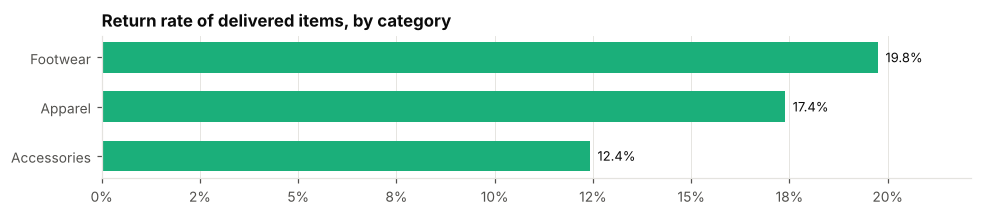

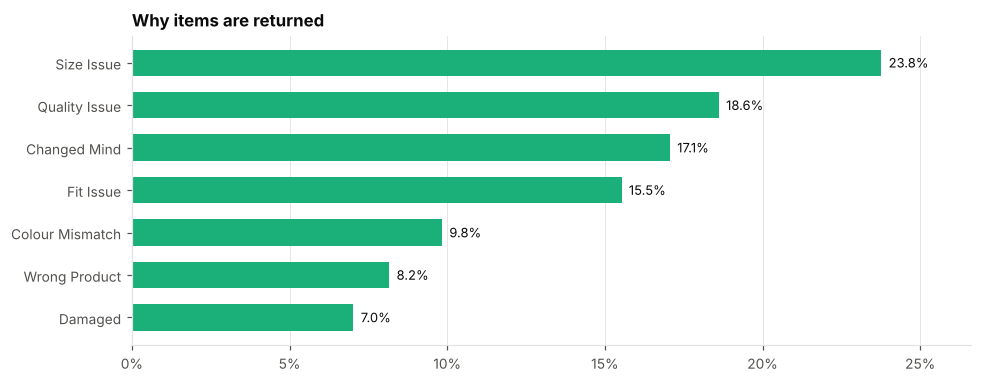

Overall return rate: 16.7%; top reason: Size Issue (24%)
Size + fit problems explain 39% of returns


In [7]:
ret = read("returns").merge(products[["product_id", "h1_category"]], on="product_id", how="left")
delivered = tx[tx.order_status.isin(["Delivered", "CIR"])].merge(products[["product_id", "h1_category"]], on="product_id")
rate = ret.groupby("h1_category").size() / delivered.groupby("h1_category").size()
hbar(rate.dropna(), "Return rate of delivered items, by category", color=SERIES[2])
reasons = ret["return_reason"].value_counts(normalize=True)
hbar(reasons, "Why items are returned", color=SERIES[2])
print(f"Overall return rate: {len(ret)/len(delivered):.1%}; top reason: {reasons.index[0]} ({reasons.iloc[0]:.0%})")
size_fit = reasons.reindex(['Size Issue', 'Fit Issue']).sum()
print(f"Size + fit problems explain {size_fit:.0%} of returns")

## 7. Which marketing channels bring valuable customers?

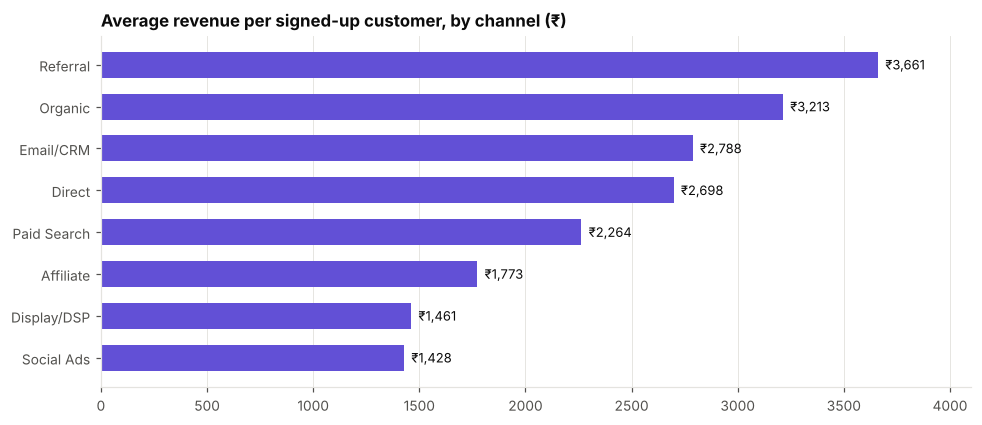

Best: Referral (₹3,661); weakest: Social Ads (₹1,428), a 2.6× gap


In [8]:
rev = realized.groupby("customer_id")["realized_revenue"].sum()
per_channel = customers.assign(revenue=customers.customer_id.map(rev).fillna(0)).groupby("acquisition_channel")["revenue"].mean()
hbar(per_channel, "Average revenue per signed-up customer, by channel (₹)", fmt="₹{:,.0f}", color=SERIES[6])
print(f"Best: {per_channel.idxmax()} (₹{per_channel.max():,.0f}); weakest: {per_channel.idxmin()} (₹{per_channel.min():,.0f}), "
      f"a {per_channel.max()/per_channel.min():.1f}× gap")

## 8. Repeat customers

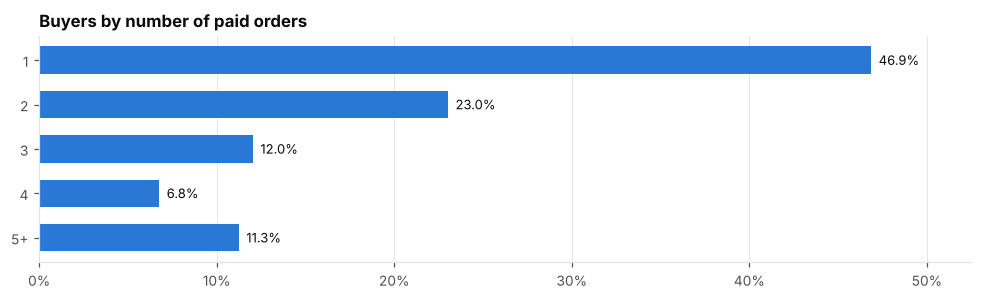

Repeat buyers: 53.1% of buyers, bringing 80.3% of revenue


In [9]:
orders_per_buyer = realized.groupby("customer_id").size()
repeat = orders_per_buyer[orders_per_buyer >= 2].index
share_repeat_rev = realized[realized.customer_id.isin(repeat)]["realized_revenue"].sum() / realized["realized_revenue"].sum()
dist = orders_per_buyer.clip(upper=5).value_counts(normalize=True).sort_index()
dist.index = [f"{i}" if i < 5 else "5+" for i in dist.index]
hbar(dist.iloc[::-1], "Buyers by number of paid orders", color=SERIES[0], sort=False)
print(f"Repeat buyers: {len(repeat)/len(orders_per_buyer):.1%} of buyers, bringing {share_repeat_rev:.1%} of revenue")

## 9. Customer lifecycle and churn

Churn (no purchase in next 90 days) among recently active customers: 47.8% of 55,483 snapshots


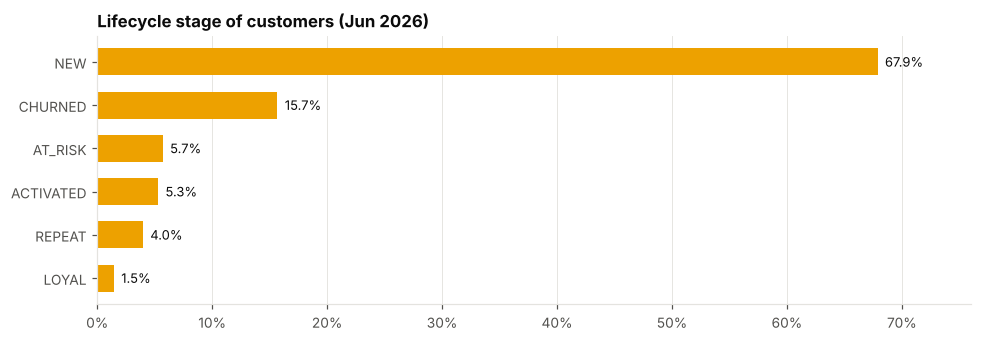

In [10]:
labels = read("customer_churn_labels")
features = read("customer_monthly_features")
print(f"Churn (no purchase in next 90 days) among recently active customers: {labels.churn_90d.mean():.1%} of {len(labels):,} snapshots")
latest = features[features.snapshot_date.eq(features.snapshot_date.max())]["lifecycle_state"].value_counts(normalize=True)
hbar(latest, f"Lifecycle stage of customers ({features.snapshot_date.max():%b %Y})", color=SERIES[3])

## 10. Recommendation evaluation
Results from `python -m recommendations.evaluate`. For every order in the held-out final period, each method ranks
the same candidate list using only what was known an hour before the order. NDCG@10 rewards putting the products
the shopper actually bought near the top (1.0 = perfect, 0 = none in the top 10).

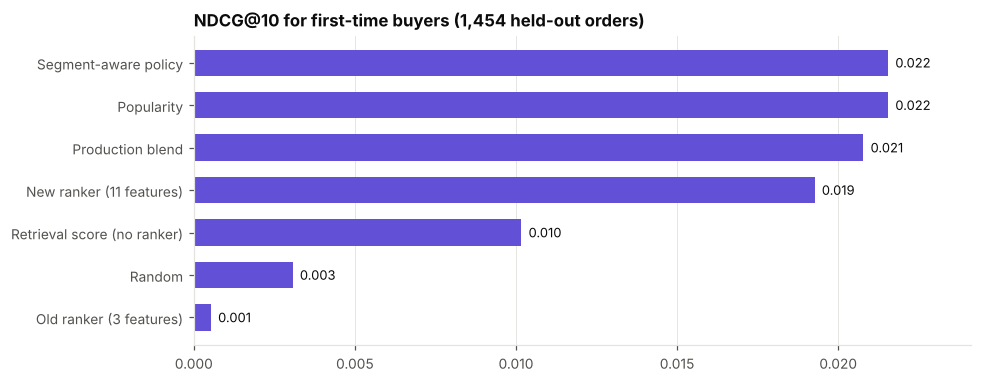

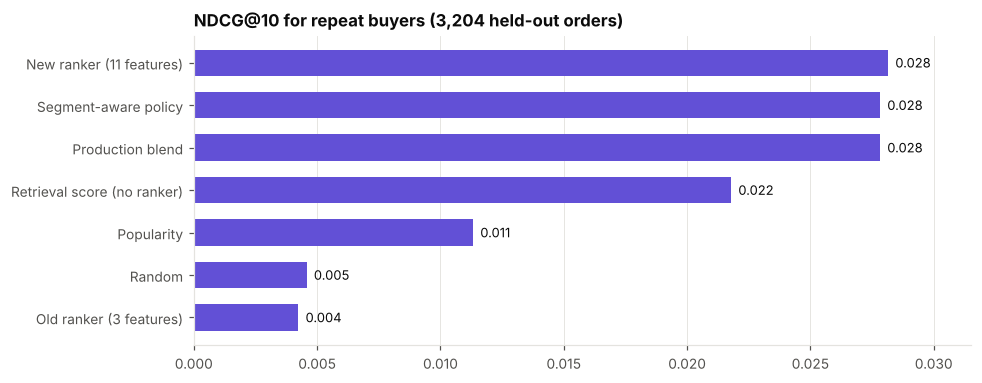

Candidate lists contained a bought product for 11.6% of test orders
new_ranker_vs_retrieval: +0.0072 (95% CI +0.0047 to +0.0099)
new_ranker_vs_popularity: +0.0109 (95% CI +0.0079 to +0.0140)
new_ranker_vs_legacy_ranker: +0.0223 (95% CI +0.0189 to +0.0261)
new_ranker_vs_random: +0.0213 (95% CI +0.0179 to +0.0250)
segment_aware_vs_retrieval: +0.0077 (95% CI +0.0055 to +0.0102)
segment_aware_vs_popularity: +0.0114 (95% CI +0.0087 to +0.0141)
segment_aware_vs_production_blend: +0.0002 (95% CI -0.0009 to +0.0013)


In [11]:
report_path = ROOT / "recommendations" / "reports" / "evaluation_report.json"
if report_path.exists():
    report = json.loads(report_path.read_text())
    names = {"random": "Random", "popularity": "Popularity", "retrieval": "Retrieval score (no ranker)",
             "legacy_ranker": "Old ranker (3 features)", "new_ranker": "New ranker (11 features)",
             "production_blend": "Production blend", "segment_aware": "Segment-aware policy"}
    for group, label in [("first_order", "first-time buyers"), ("repeat_order", "repeat buyers")]:
        res = report["results"]["end_to_end"][group]
        ndcg = pd.Series({names[o]: m["@10"]["ndcg"] for o, m in res["orderings"].items() if m["@10"]})
        hbar(ndcg, f"NDCG@10 for {label} ({res['orders']:,} held-out orders)", fmt="{:.3f}", color=SERIES[6])
    r = report["retrieval"]
    print(f"Candidate lists contained a bought product for {r['pool_coverage']:.1%} of test orders")
    for name, c in report["comparisons_ndcg10"].items():
        print(f"{name}: {c['mean_diff']:+.4f} (95% CI {c['ci_low']:+.4f} to {c['ci_high']:+.4f})")
else:
    print("Run `python -m recommendations.evaluate` first.")